In [1]:
# data loading
import os
import kagglehub

# data handling
import numpy as np
import pandas as pd

# preprocessing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

# models and cross-validation
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict

# evaluation and plots
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay)

In [2]:
# reading data
handle = "krishnaraj30/finance-loan-approval-prediction-data"

path = kagglehub.dataset_download(handle)
print(os.listdir(path))

Using Colab cache for faster access to the 'finance-loan-approval-prediction-data' dataset.
['train.csv', 'test.csv']


In [3]:
# train test
train = pd.read_csv(os.path.join(path, "train.csv"))  # adjust names to match kaggle input
test = pd.read_csv(os.path.join(path, "test.csv"))


**EDA**

In [4]:
# inspecting train data
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [5]:
# inspecting train data
train.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [6]:
train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [7]:
train.isna().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


* Training data has 614 rows and 13 columns. Loan_Status column is our target feature.

* Missingness in training data is low to moderate. Credit_History is where the largest missingness is. This column is our strongest predictor, so we must find out if the missingness itself is related to approval.

* Missingness Methods

- Credit_History : If missingness group's approval rate differs from the 1 and 0 groups, keep as it's own category eg 'Unknown' instead of imputing.

- Gender, Married, Dependent, Self Employed : Most Frequent Values

- Loan_Amount : Right skewed data, fill with median.

- Loan_Amount_Term: Fill with mode.


In [8]:
# inspecting our data
print(train.shape, test.shape)
print(set(train.columns) - set(test.columns)) # shows which column is missing

(614, 13) (367, 12)
{'Loan_Status'}


* We can see here that the test data is missing a target feature column 'Loan_Status'. This is because this was a kaggle submission file, and the labels were kept hidden for scoring.

* Our solution for this issue is to use the train data as the entire dataframe, and re split it into train and test.

In [9]:
# Split train test
train_df, test_df = train_test_split(
    train, test_size=0.2, stratify=train["Loan_Status"], random_state=123
)
print(train_df.shape, test_df.shape)
print(set(train_df.columns) - set(test_df.columns))

(491, 13) (123, 13)
set()


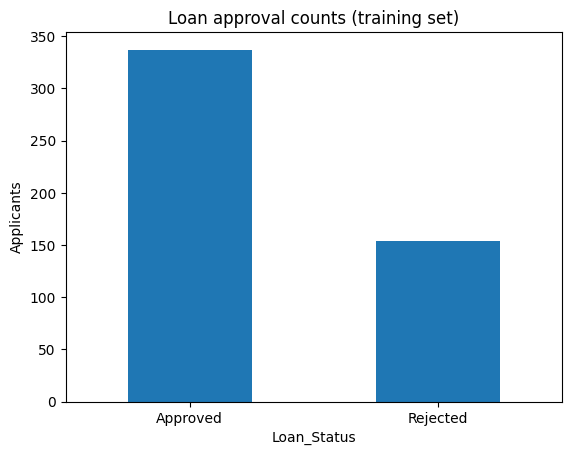

In [10]:
train_df["Loan_Status"].value_counts().plot.bar()
plt.title("Loan approval counts (training set)")
plt.xticks([0, 1], ["Approved", "Rejected"], rotation=0)
plt.ylabel("Applicants");

Target distribution: shows an imbalance of loan approval data. hence the need for the baseline.

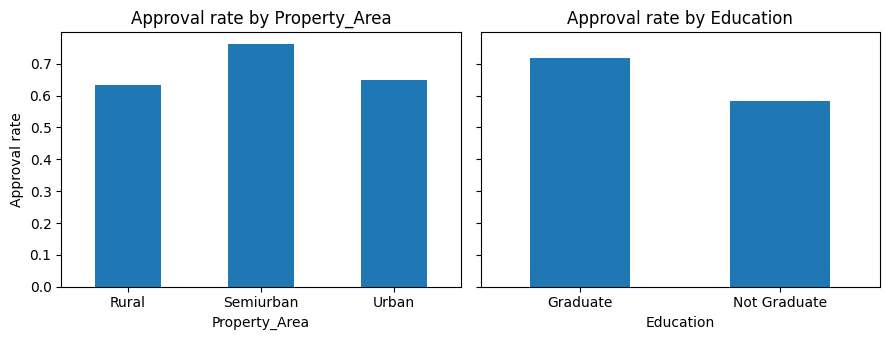

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for a, col in zip(ax, ["Property_Area", "Education"]):
    (train_df.groupby(col)["Loan_Status"]
       .apply(lambda s: (s == "Y").mean())
       .plot.bar(ax=a, rot=0, title=f"Approval rate by {col}"))
ax[0].set_ylabel("Approval rate")
plt.tight_layout();

Semiurban and Graduates are approved more often.

**Data Preprocessing**

In [12]:
# row-wise cleaning and feature engineering
def prepare(df):
  df = df.copy()
  # dependents 3+ becomes 3 (numeric)
  df['Dependents'] = df['Dependents'].replace("3+", "3").astype(float)

  # credit history: keep missingness as it's own category
  df["Credit_History"] = (df["Credit_History"]
                            .map({1.0: "Good", 0.0: "Bad"})
                            .fillna("Unknown"))

  # engineered features
  df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
  df["LoanToIncome"] = df["LoanAmount"] / df["TotalIncome"].replace(0, np.nan)
  return df

In [13]:
train_p = prepare(train_df)
test_p = prepare(test_df)

We are mindful of data leakage, and to ahdhere to the golden rule. The data preparation is applied to both the train and test set so that the model can score the data on the same format it's trained on.

prepare function does not learn anything from the data, each row output is dependent on it's own row.

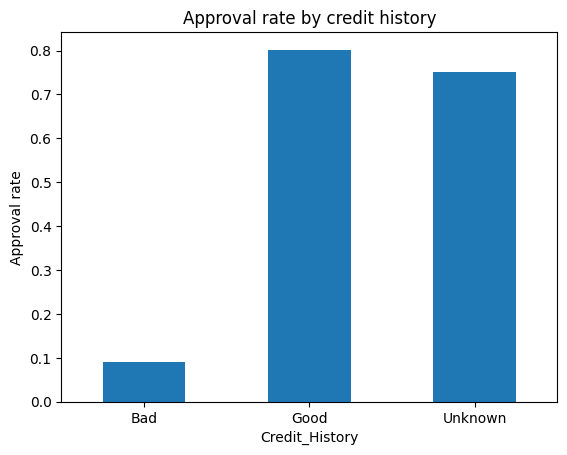

In [14]:
train_eda = prepare(train_df)
(train_eda.groupby("Credit_History")["Loan_Status"]
   .apply(lambda s: (s == "Y").mean())
   .plot.bar(rot=0))
plt.title("Approval rate by credit history")
plt.ylabel("Approval rate");

Bad Credit is almost never approved, while unknown is close to good. Missing credit is therefore kept as it's own category.

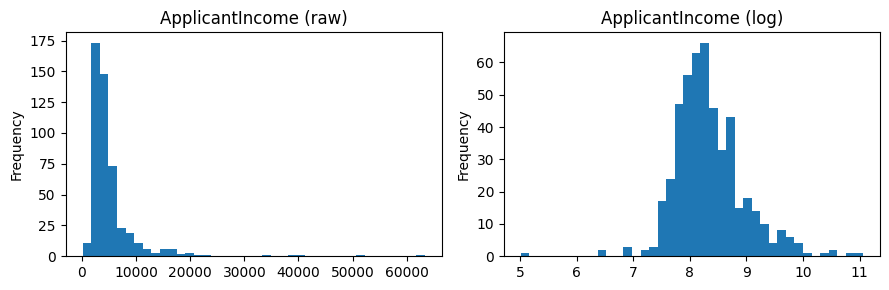

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
train_df["ApplicantIncome"].plot.hist(bins=40, ax=ax[0], title="ApplicantIncome (raw)")
np.log1p(train_df["ApplicantIncome"]).plot.hist(bins=40, ax=ax[1], title="ApplicantIncome (log)")
plt.tight_layout();

Applicant income is very right skewed with a few high income earners, so the log transform makes it roughly symmetric. so income and loan features are log-transformed before scaling.

In [16]:
# features and target
y_train = (train_p["Loan_Status"] == "Y").astype(int)
y_test = (test_p["Loan_Status"] == "Y").astype(int)

In [17]:
skewed_cols = ["ApplicantIncome", "CoapplicantIncome", "TotalIncome",
               "LoanAmount", "LoanToIncome"]
other_num_cols = ["Loan_Amount_Term", "Dependents"]
cat_cols = ["Education", "Self_Employed", "Property_Area", "Credit_History"]


Gender and Married is left out on purpose. (fair lending concern)

In [18]:
feature_cols = skewed_cols + other_num_cols + cat_cols
X_train = train_p[feature_cols]
X_test = test_p[feature_cols]

In [19]:
# Column Transformers (fit on train)
skewed_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
    StandardScaler(),
)
other_num_pipe = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    StandardScaler(),
)
cat_pipe = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False),
)

preprocess = ColumnTransformer([
    ("skewed", skewed_pipe, skewed_cols),
    ("num", other_num_pipe, other_num_cols),
    ("cat", cat_pipe, cat_cols),
])

In [20]:
# quick sanity check: checking if the encoder works the way it was intended.
X_train_sanity = preprocess.fit_transform(X_train)
print(X_train_sanity.shape)
print(preprocess.get_feature_names_out())
print(np.isnan(X_train_sanity).sum())  # expected result: 0

(491, 15)
['skewed__ApplicantIncome' 'skewed__CoapplicantIncome'
 'skewed__TotalIncome' 'skewed__LoanAmount' 'skewed__LoanToIncome'
 'num__Loan_Amount_Term' 'num__Dependents' 'cat__Education_Not Graduate'
 'cat__Self_Employed_Yes' 'cat__Property_Area_Rural'
 'cat__Property_Area_Semiurban' 'cat__Property_Area_Urban'
 'cat__Credit_History_Bad' 'cat__Credit_History_Good'
 'cat__Credit_History_Unknown']
0


**Baseline Model**

In [21]:
dummy = Pipeline([("preprocess", preprocess),
                  ("clf", DummyClassifier(strategy="most_frequent"))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

dummy_scores = cross_validate(dummy, X_train, y_train, cv=cv,
                              scoring=["accuracy", "f1", "roc_auc"])
pd.DataFrame(dummy_scores)[["test_accuracy", "test_f1", "test_roc_auc"]].mean().round(3)

,0
test_accuracy,0.686
test_f1,0.814
test_roc_auc,0.500


**Logistic Regression: 5 fold CV**

In [22]:
model = Pipeline([
    ("preprocess", preprocess),
    ("clf", LogisticRegression(max_iter=1000)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
scores = cross_validate(model, X_train, y_train, cv=cv,
                        scoring=["accuracy", "f1", "roc_auc"])

(pd.DataFrame(scores)[["test_accuracy", "test_f1", "test_roc_auc"]]
   .mean().round(3)
   .rename({"test_accuracy": "Accuracy", "test_f1": "F1", "test_roc_auc": "ROC AUC"})
   .to_frame("Logistic regression (5-fold CV mean)"))

,Logistic regression (5-fold CV mean)
Accuracy,0.809
F1,0.874
ROC AUC,0.762


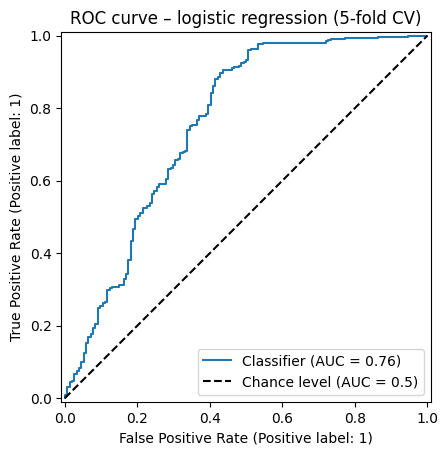

In [23]:
y_score = cross_val_predict(model, X_train, y_train, cv=cv, method = 'predict_proba')[:, 1]

RocCurveDisplay.from_predictions(y_train, y_score, plot_chance_level = True);
plt.title("ROC curve – logistic regression (5-fold CV)");

Interpreting and comparing the CrossFold validation fit results.
F1 improved modestly due to 'approved' already being inflated.
AUC-ROC most meaningful improvement.


**Final Fit**

In [24]:
model.fit(X_train, y_train)
test_pred = model.predict(X_test)
test_prob = model.predict_proba(X_test)[:, 1]

pd.Series({
    "Accuracy": accuracy_score(y_test, test_pred),
    "F1": f1_score(y_test, test_pred),
    "ROC AUC": roc_auc_score(y_test, test_prob),
}).round(3).to_frame("Logistic regression (test set)")

,Logistic regression (test set)
Accuracy,0.789
F1,0.867
ROC AUC,0.711


              precision    recall  f1-score   support

    Rejected       1.00      0.32      0.48        38
    Approved       0.77      1.00      0.87        85

    accuracy                           0.79       123
   macro avg       0.88      0.66      0.67       123
weighted avg       0.84      0.79      0.75       123



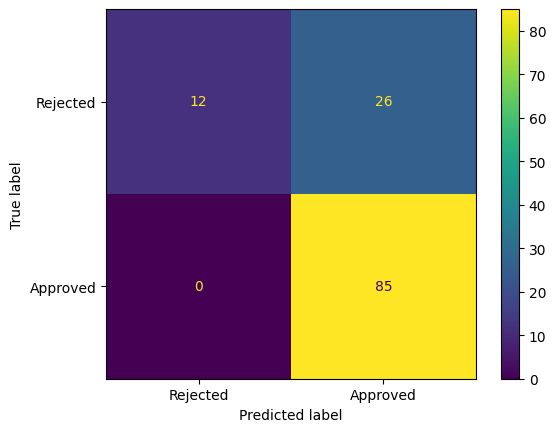

In [25]:
print(classification_report(y_test, test_pred, target_names=["Rejected", "Approved"]))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred,
                                        display_labels=["Rejected", "Approved"]);

Interpret the confusion matrix. Note the limitations of the model and which mistake costs more: for a lender a bad loan vs a lost customer.

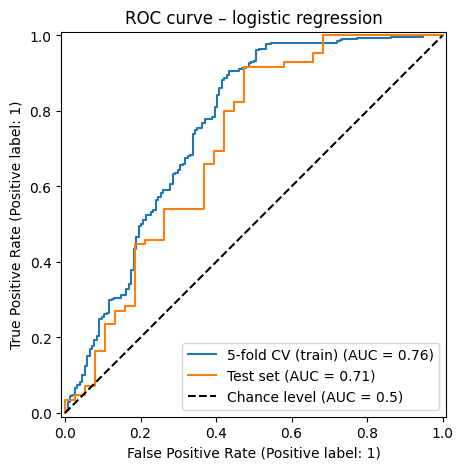

In [26]:
fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_train, y_score, name="5-fold CV (train)", ax=ax)
RocCurveDisplay.from_predictions(y_test, test_prob, name="Test set", ax=ax,
                                 plot_chance_level=True)
plt.title("ROC curve – logistic regression");

we have 2 roc curves here. one with CV and one with test set. the test curve is more jagged because it's based on only 123 applicants (38 rejections). so each applicant shifts the curve by a larger step. For the same reason, the test AUC is less precise than the cross-validated AUC.

**Customer Segmentation**

which features drive approval? Which variables are worth using to define segments.

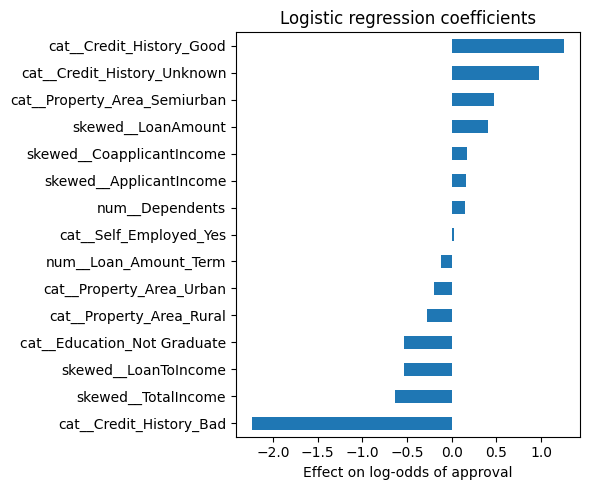

In [27]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(model.named_steps["clf"].coef_[0], index=feature_names).sort_values()

coefs.plot.barh(figsize=(6, 5))
plt.title("Logistic regression coefficients")
plt.xlabel("Effect on log-odds of approval")
plt.tight_layout();

graph explaination: each bar shows how much a feature pushes the model toward approval (right) or rejection (left). The units are log-odds. These coefficients show which features are the main driver for the model's predictions.